In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

In [2]:
data = pd.read_csv('C:\\Users\\lefte\\datasets\\fraud_card.csv')

In [3]:
data.head(10)

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0
5,6,30.53,13,Clothing,0,0,90,2,46,0
6,7,10.77,18,Travel,0,0,48,1,28,0
7,8,362.02,13,Electronics,0,0,68,1,40,0
8,9,165.43,8,Grocery,0,0,80,0,21,0
9,10,221.63,5,Grocery,0,0,59,1,34,0


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  str    
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), str(1)
memory usage: 781.4 KB


In [5]:
data.describe()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,175.949849,11.593300,0.097800,0.085700,61.798900,2.008900,43.468700,0.015100
std,2886.89568,175.392827,6.922708,0.297059,0.279935,21.487053,1.432559,14.979147,0.121957
min,1.00000,0.000000,0.000000,0.000000,0.000000,25.000000,0.000000,18.000000,0.000000
25%,2500.75000,50.905000,6.000000,0.000000,0.000000,43.000000,1.000000,30.000000,0.000000
50%,5000.50000,122.095000,12.000000,0.000000,0.000000,62.000000,2.000000,44.000000,0.000000
75%,7500.25000,242.480000,18.000000,0.000000,0.000000,80.000000,3.000000,56.000000,0.000000
max,10000.00000,1471.040000,23.000000,1.000000,1.000000,99.000000,9.000000,69.000000,1.000000


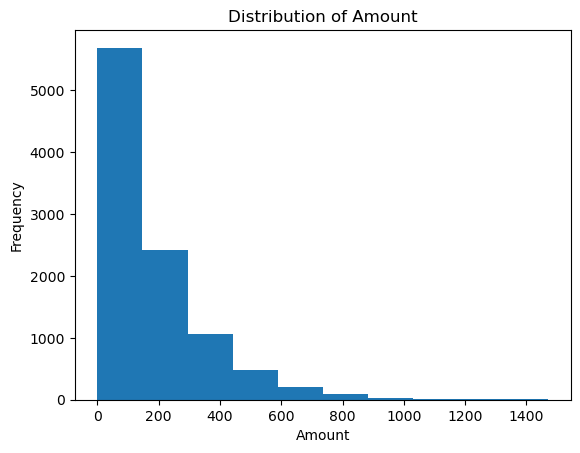

In [29]:
plt.hist(data['amount'], bins=10)
plt.ylabel('Frequency')
plt.xlabel('Amount')
plt.title('Distribution of Amount')
plt.show()


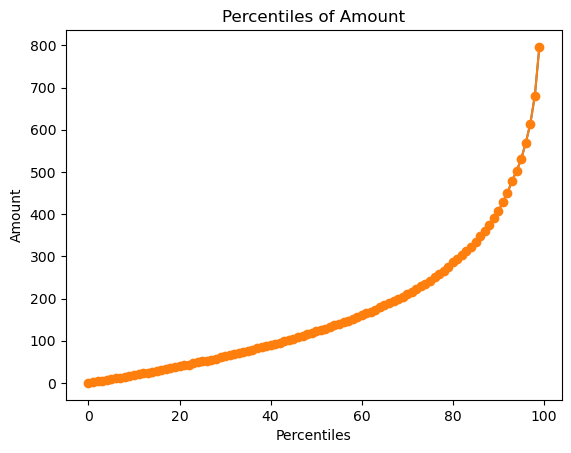

In [32]:
percentiles = np.arange(0, 100, 1)
values = np.percentile(data['amount'], percentiles) 
plt.plot(percentiles, values)
plt.plot(percentiles, values, marker='o')
plt.xlabel('Percentiles')
plt.ylabel('Amount')
plt.title('Percentiles of Amount')
plt.show()

Outliers Detection

Formula
IQR = Q3 − Q1
Outliers:
below → Q1 − 1.5 × IQR
above → Q3 + 1.5 × IQR

In [34]:
q1 = data['amount'].quantile(0.25)
q3 = data['amount'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = data[(data['amount'] < lower_bound) | (data['amount'] > upper_bound)]
print(outliers)
print("Number of outliers:", len(outliers))

      transaction_id   amount  transaction_hour merchant_category  \
1                  2   541.82                 3            Travel   
11                12   630.64                18          Clothing   
33                34   535.26                 6          Clothing   
34                35   606.71                 7            Travel   
50                51   628.71                 4          Clothing   
...              ...      ...               ...               ...   
9851            9852   649.44                17            Travel   
9927            9928  1370.04                 7           Grocery   
9971            9972   671.94                16            Travel   
9972            9973   566.35                 0       Electronics   
9978            9979   541.45                 5           Grocery   

      foreign_transaction  location_mismatch  device_trust_score  \
1                       1                  0                  87   
11                      0          

In [36]:
outliers['is_fraud'].value_counts()

is_fraud
0    486
1     15
Name: count, dtype: int64

In [50]:
print("Fraudulent transactions represent", round((15/len(outliers)) * 100, 2), "% of the outlier data")

Fraudulent transactions represent 2.99 % of the outlier data


In [48]:
data["is_fraud"].value_counts()

is_fraud
0    9849
1     151
Name: count, dtype: int64

In [51]:
print("Fraudulent transactions represent", round((151/len(data)) * 100, 2), "% of the whole data")

Fraudulent transactions represent 1.51 % of the whole data


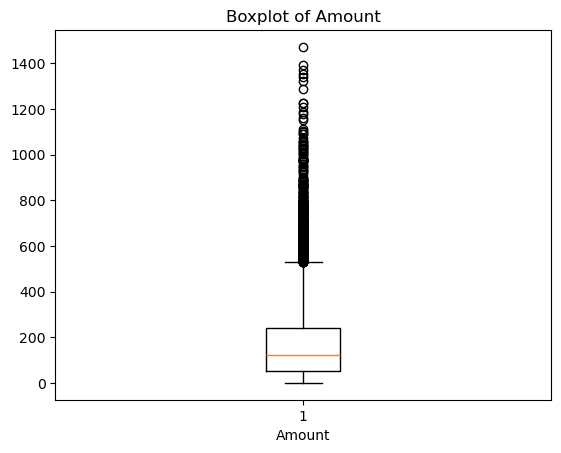

In [37]:
plt.boxplot(x=data['amount'])
plt.title('Boxplot of Amount')
plt.xlabel('Amount')    
plt.show()

In [52]:
data["is_outlier"] = (data["amount"] < lower_bound) | (data["amount"] > upper_bound)
data["is_outlier"].value_counts()

is_outlier
False    9499
True      501
Name: count, dtype: int64

In [55]:
data.columns

Index(['transaction_id', 'amount', 'transaction_hour', 'merchant_category',
       'foreign_transaction', 'location_mismatch', 'device_trust_score',
       'velocity_last_24h', 'cardholder_age', 'is_fraud', 'is_outlier'],
      dtype='str')

In [56]:
data.isnull().sum()

transaction_id         0
amount                 0
transaction_hour       0
merchant_category      0
foreign_transaction    0
location_mismatch      0
device_trust_score     0
velocity_last_24h      0
cardholder_age         0
is_fraud               0
is_outlier             0
dtype: int64

In [57]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  str    
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
 10  is_outlier           10000 non-null  bool   
dtypes: bool(1), float64(1), int64(8), str(1)
memory usage: 791.1 KB


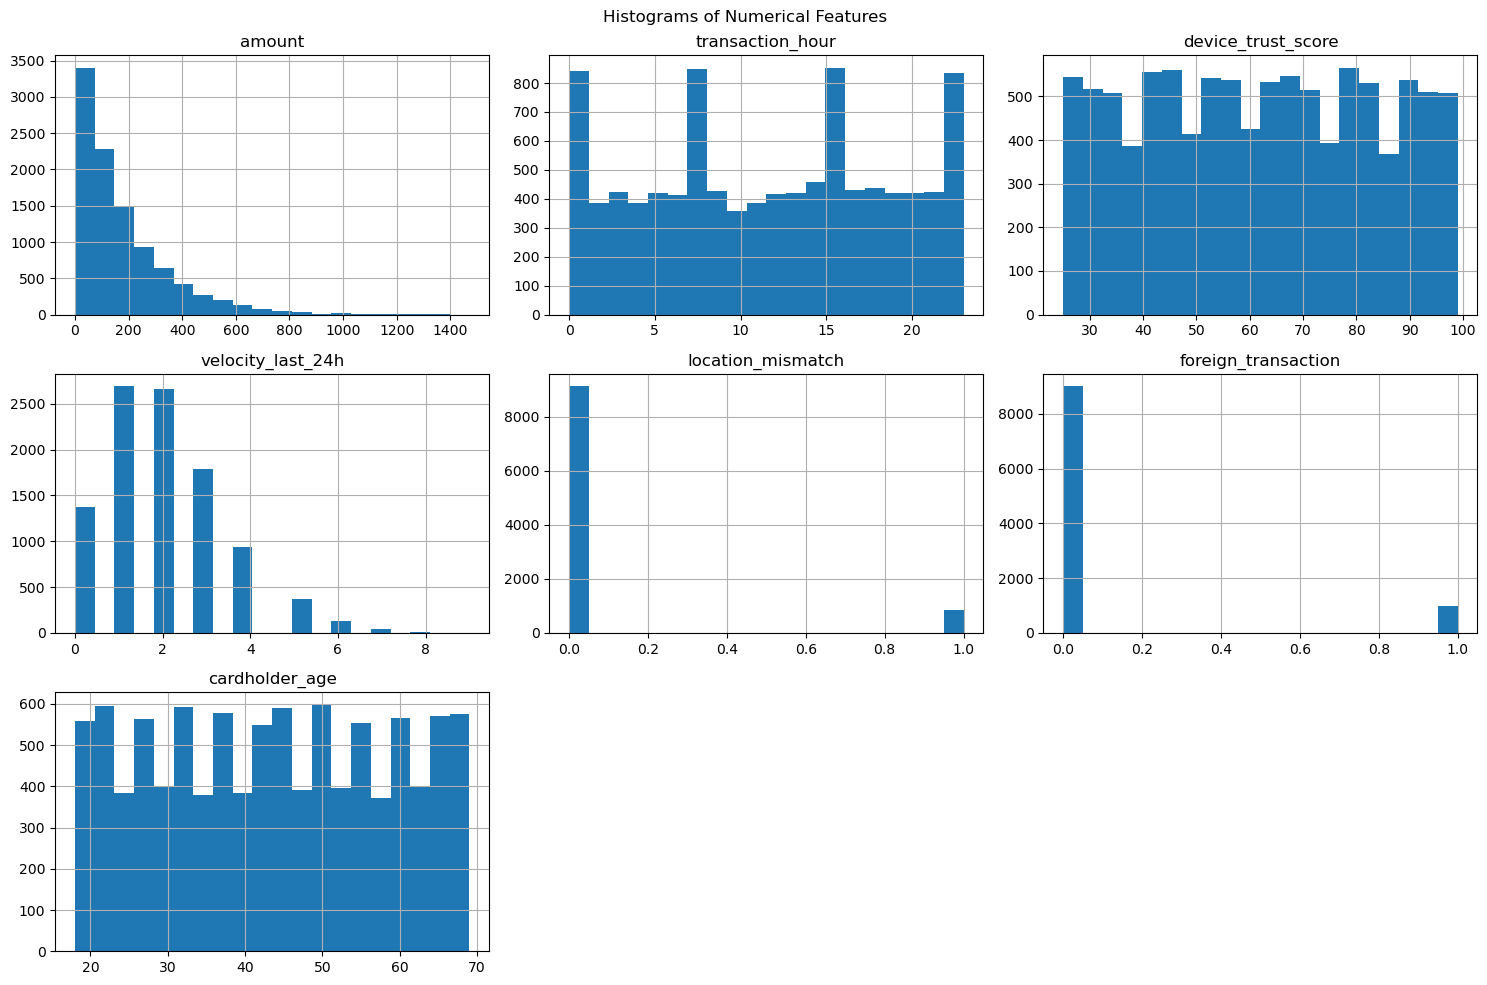

In [79]:
num_cols = [
    'amount',
    'transaction_hour',
    'device_trust_score',
    'velocity_last_24h',
    'location_mismatch',
    'foreign_transaction',
    'cardholder_age',
]


data[num_cols].hist(bins=20, figsize=(15, 10))
plt.suptitle('Histograms of Numerical Features')
plt.tight_layout()
plt.show()

is_fraud
0    9849
1     151
Name: count, dtype: int64
is_outlier
False    9499
True      501
Name: count, dtype: int64


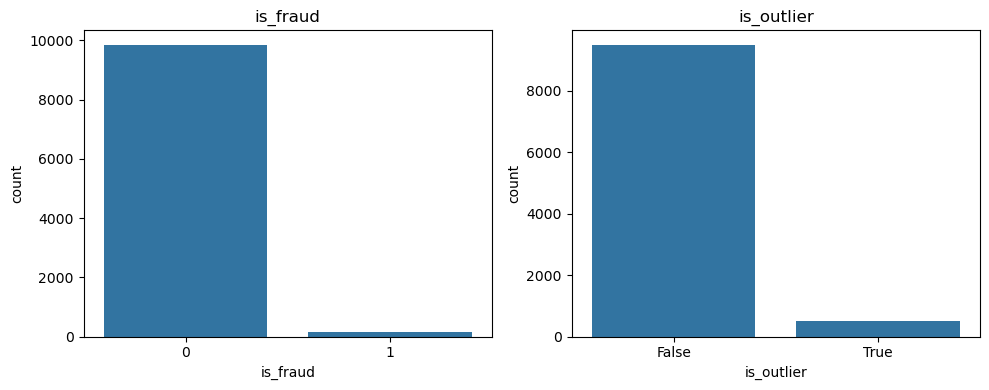

In [ ]:
cat_cols = [
    'is_fraud',
    'is_outlier'
]

for i in cat_cols:
    print(data[i].value_counts())



fig, axes = plt.subplots(1, len(cat_cols), figsize=(10, 4))

for i, y in enumerate(cat_cols):
    sns.countplot(x=data[y], ax=axes[i])
    axes[i].set_title(y)

plt.tight_layout()
plt.show()

In [96]:
data.groupby('foreign_transaction')['is_fraud'].mean().round(4)



foreign_transaction
0    0.0076
1    0.0838
Name: is_fraud, dtype: float64

In [97]:
data.groupby('merchant_category')['is_fraud'].mean().sort_values(ascending=False).round(4)

merchant_category
Grocery        0.0201
Food           0.0167
Travel         0.0146
Electronics    0.0125
Clothing       0.0117
Name: is_fraud, dtype: float64

In [99]:
data.groupby('location_mismatch')['is_fraud'].mean().round(5)


location_mismatch
0    0.00864
1    0.08401
Name: is_fraud, dtype: float64

In [103]:
data.groupby('device_trust_score')['is_fraud'].mean().round(5)


device_trust_score
25    0.06923
26    0.04225
27    0.07092
28    0.09848
29    0.05147
       ...   
95    0.00704
96    0.00000
97    0.00000
98    0.00725
99    0.00800
Name: is_fraud, Length: 75, dtype: float64

In [108]:
data.groupby('cardholder_age')['is_fraud'].mean().sort_values(ascending=False).round(5)


cardholder_age
41    0.03409
44    0.03398
20    0.02941
35    0.02703
45    0.02538
52    0.02488
29    0.02326
58    0.02299
46    0.02151
38    0.02139
30    0.02139
51    0.02128
18    0.02073
63    0.02062
53    0.02051
37    0.02030
57    0.02010
28    0.01932
65    0.01905
66    0.01829
55    0.01714
67    0.01639
27    0.01613
43    0.01604
23    0.01579
33    0.01579
69    0.01562
36    0.01554
21    0.01538
59    0.01531
32    0.01508
40    0.01463
61    0.01149
56    0.01087
24    0.01087
34    0.01031
60    0.01020
25    0.01005
48    0.01005
49    0.01000
31    0.00985
62    0.00971
50    0.00948
54    0.00513
19    0.00510
64    0.00508
68    0.00500
26    0.00000
22    0.00000
47    0.00000
39    0.00000
42    0.00000
Name: is_fraud, dtype: float64

In [109]:
data.columns

Index(['transaction_id', 'amount', 'transaction_hour', 'merchant_category',
       'foreign_transaction', 'location_mismatch', 'device_trust_score',
       'velocity_last_24h', 'cardholder_age', 'is_fraud', 'is_outlier'],
      dtype='str')

In [111]:
data.groupby('transaction_hour')['is_fraud'].mean().sort_values(ascending=False).round(5)


transaction_hour
0     0.08873
1     0.08000
3     0.06353
2     0.05974
19    0.00950
23    0.00716
8     0.00708
11    0.00519
6     0.00484
20    0.00477
5     0.00477
13    0.00476
17    0.00466
15    0.00463
10    0.00279
4     0.00260
21    0.00236
9     0.00235
18    0.00228
14    0.00218
7     0.00000
12    0.00000
16    0.00000
22    0.00000
Name: is_fraud, dtype: float64